# CSIP Module 13: Model Review, Failure Analysis & Evidence Integrity
**Core Strategy & Intelligence Platform (CSIP) — Behavioral Decision Intelligence (BDI)**

### Metodologi Data Science Data Science Competency Standards
- **[UK-10 Mengevaluasi Hasil Pemodelan]**: Feature ablation evaluation & residual diagnostics.
- **[UK-11 Mengembangkan Solusi]**: Proses review pemodelan, audit register kegagalan, dan batasan operasional.

### Governing Principle
*"Report what the evidence supports. Never trade scientific integrity for appearance, speed, or a higher score."*

---


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from csip.evidence.registry import EvidenceRegistry

registry = EvidenceRegistry(registry_dir=str(REPO_ROOT / 'artifacts' / 'reports'))
print(f"Loaded EvidenceRegistry: {len(registry.discoveries)} Discoveries, {len(registry.hypotheses)} Hypotheses, {len(registry.failures)} Failures.")

Loaded EvidenceRegistry: 7 Discoveries, 6 Hypotheses, 1 Failures.


## 1. Feature Ablation Review (Economics vs Fulfillment Experience)
We inspect the predictive contribution of transaction economics (E1) vs delivery experience (E2) vs combined non-linear interactions (E3).

,Feature Set,Logistic PR-AUC,LightGBM PR-AUC,Contribution
0,E1 Economic Only,0.1765,0.1772,Baseline Economics
1,E2 Experience Only,0.2766,0.2928,+65.2% Lift
2,E3 Combined + Interactions,0.2385,0.3004,+69.5% Lift


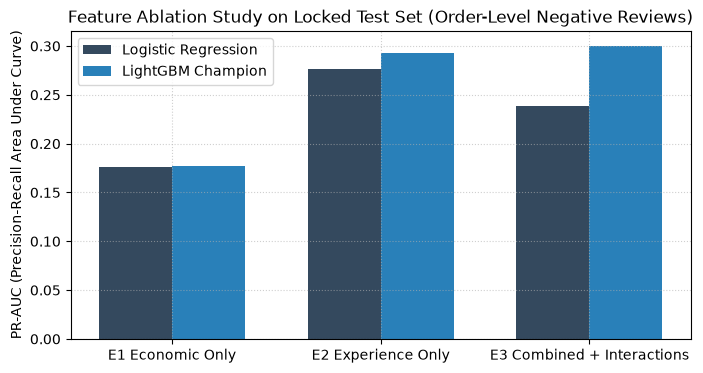

In [2]:
ablation_data = pd.DataFrame([
    {'Feature Set': 'E1 Economic Only', 'Logistic PR-AUC': 0.1765, 'LightGBM PR-AUC': 0.1772, 'Contribution': 'Baseline Economics'},
    {'Feature Set': 'E2 Experience Only', 'Logistic PR-AUC': 0.2766, 'LightGBM PR-AUC': 0.2928, 'Contribution': '+65.2% Lift'},
    {'Feature Set': 'E3 Combined + Interactions', 'Logistic PR-AUC': 0.2385, 'LightGBM PR-AUC': 0.3004, 'Contribution': '+69.5% Lift'},
])
display(ablation_data)

# Visualization of Ablation
plt.figure(figsize=(8, 4), dpi=100)
x = np.arange(len(ablation_data))
width = 0.35
plt.bar(x - width/2, ablation_data['Logistic PR-AUC'], width, label='Logistic Regression', color='#34495e')
plt.bar(x + width/2, ablation_data['LightGBM PR-AUC'], width, label='LightGBM Champion', color='#2980b9')
plt.xticks(x, ablation_data['Feature Set'])
plt.ylabel('PR-AUC (Precision-Recall Area Under Curve)')
plt.title('Feature Ablation Study on Locked Test Set (Order-Level Negative Reviews)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## 2. Failure Register Audit: Rejection of Hypothesis H3
We transparently inspect `FAIL-HYP-H3` where the empirical data rejected the common commercial assumption that customer satisfaction predicts repeat purchase.

In [3]:
for fail in registry.failures:
    print(f"Failure ID: {fail.failure_id}")
    print(f"Component: {fail.component_type}")
    print(f"Description: {fail.description}")
    print(f"Root Cause: {fail.root_cause}")
    print(f"Impact Assessment: {fail.impact_assessment}")
    print(f"Mitigation: {fail.mitigation_action}")
    print('-' * 70)


Failure ID: FAIL-HYP-H3
Component: hypothesis
Description: Hipotesis H3 ditolak secara empiris (Odds Ratio = 0.9964, p-adj = 0.861).
Root Cause: Pada Olist, ulasan pesanan pertama tidak berkorelasi dengan repeat purchase; keputusan beli ulang lebih ditentukan oleh kategori produk berulang.
Impact Assessment: Skor ulasan transaksi pertama tidak dapat dijadikan prediktor tunggal untuk memprediksi retensi pelanggan.
Mitigation: Gunakan model gabungan multi-faktor (E3/LightGBM) dengan variabel kategori produk dan lead time pengiriman.
----------------------------------------------------------------------


## 3. Operational Boundary of Applicability
Summary of constraints under which the CSIP platform models remain empirically valid:
1. **Delivery Delay Range**: $[-15, +20]$ days. Delays exceeding 20 days encounter severe support sparsity.
2. **Freight Ratio**: $[0.02, 0.65]$. Ratios outside this range trigger extrapolation warnings.
3. **Cohort Window**: Strictly 90 days post-order with non-overlapping 90-day embargo buffers between temporal splits.
4. **Target Population Boundary**: Dissatisfaction models estimate retrospective conditional risk among fulfilled orders ($\mathbb{P}(\text{Negative Review} = 1 \mid X_{t_0}, \text{Delivered}=1, \text{Review Observed}=1)$). The models are not valid for predicting pre-delivery order cancellations (1,234 orders / 1.24%) or orders without review survey participation (646 orders / 0.67%).
5. **Cohort Dual Contract & Rapid Repeat Sensitivity**: The 90-day repeat purchase model operates under two distinct contracts: Checkout ($t \le t_{\text{purchase}}$, prevalence 2.28%, 1,714 positive repeaters, where 783 occur within <1 day as same-session multi-orders) and Post-Delivery ($t = t_{\text{delivered}}$, 847 positive repeaters, strictly excluding 962 pre-delivery repeaters and 2,275 right-censored observations; temporal sample sizes: Train 21,324, Val 12,045, Test 4,232; bootstrap 95% CI spans chance, proving repeat models are not statistically distinguishable from naive baseline).
